# Experiment 2 — Data Preprocessing (House Price Dataset)

**Covers:** Missing values, label encoding, one-hot encoding, standardization, Min-Max scaling, box plot, IQR table, outlier removal and CSV export.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** Missing → Encoding → Scaling → Boxplot → IQR → Remove → Save.

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

df = pd.read_csv("housing.csv")

## 1. Missing values

In [2]:
print(df.shape)
print(pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": df.isnull().mean() * 100
}))

num = ["housing_median_age", "total_rooms", "total_bedrooms", "population",
       "households", "median_income"]
cat = ["ocean_proximity"]

for col in num:
    df[col] = df[col].fillna(df[col].median())

for col in cat:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df[num + cat].isnull().sum())

(20640, 10)
                    Missing   Percent
longitude                 0  0.000000
latitude                  0  0.000000
housing_median_age        0  0.000000
total_rooms               0  0.000000
total_bedrooms          207  1.002907
population                0  0.000000
households                0  0.000000
median_income             0  0.000000
median_house_value        0  0.000000
ocean_proximity           0  0.000000
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64


## 2. Encoding (one-hot and label encoding)

In [3]:
print(pd.get_dummies(df[cat], drop_first=True, dtype=int).head())

df["ocean_proximity_encoded"] = LabelEncoder().fit_transform(df["ocean_proximity"])
print(df[["ocean_proximity", "ocean_proximity_encoded"]].drop_duplicates())

   ocean_proximity_INLAND  ocean_proximity_ISLAND  ocean_proximity_NEAR BAY  \
0                       0                       0                         1   
1                       0                       0                         1   
2                       0                       0                         1   
3                       0                       0                         1   
4                       0                       0                         1   

   ocean_proximity_NEAR OCEAN  
0                           0  
1                           0  
2                           0  
3                           0  
4                           0  


     ocean_proximity  ocean_proximity_encoded
0           NEAR BAY                        3
701        <1H OCEAN                        0
954           INLAND                        1
1850      NEAR OCEAN                        4
8314          ISLAND                        2


## 3. Scaling (standardization and Min-Max)

In [4]:
std = pd.DataFrame(StandardScaler().fit_transform(df[num]), columns=num)
mm = pd.DataFrame(MinMaxScaler().fit_transform(df[num]), columns=num)

print(std.agg(["mean", "std"]).round(2))
print(mm.agg(["min", "max"]))

      housing_median_age  total_rooms  total_bedrooms  population  households  \
mean                 0.0          0.0            -0.0        -0.0         0.0   
std                  1.0          1.0             1.0         1.0         1.0   

      median_income  
mean            0.0  
std             1.0  


     housing_median_age  total_rooms  total_bedrooms  population  households  \
min                 0.0          0.0             0.0         0.0         0.0   
max                 1.0          1.0             1.0         1.0         1.0   

     median_income  
min            0.0  
max            1.0  


## 4. Box plot

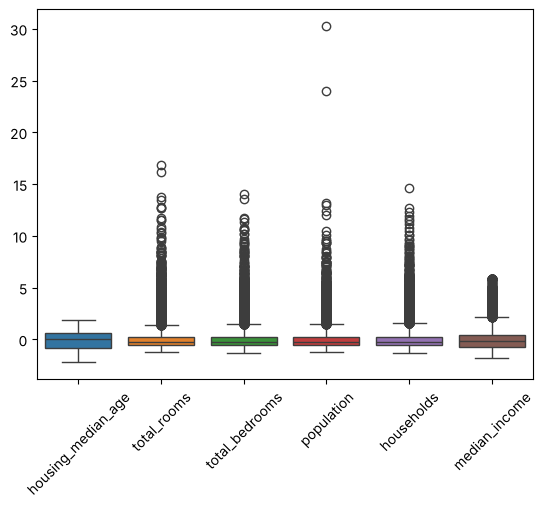

In [5]:
sns.boxplot(data=std)
plt.xticks(rotation=45)
plt.show()

## 5. IQR table

In [6]:
rows = []
for col in num:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, count])

table = pd.DataFrame(rows, columns=[
    "Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"
])
print(table)

               Column         Q1          Q3         IQR        Lower  \
0  housing_median_age    18.0000    37.00000    19.00000   -10.500000   
1         total_rooms  1447.7500  3148.00000  1700.25000 -1102.625000   
2      total_bedrooms   297.0000   643.25000   346.25000  -222.375000   
3          population   787.0000  1725.00000   938.00000  -620.000000   
4          households   280.0000   605.00000   325.00000  -207.500000   
5       median_income     2.5634     4.74325     2.17985    -0.706375   

         Upper  Outliers  
0    65.500000         0  
1  5698.375000      1287  
2  1162.625000      1306  
3  3132.000000      1196  
4  1092.500000      1220  
5     8.013025       681  


## 6. Remove outliers from `median_income` and save

In [7]:
low = table.set_index("Column").loc["median_income", "Lower"]
high = table.set_index("Column").loc["median_income", "Upper"]

clean = df[df["median_income"].between(low, high)]
print("Before:", len(df), "After:", len(clean))

clean.to_csv("clean.csv", index=False)
print("Saved clean.csv")

Before: 20640 After: 19959


Saved clean.csv


## Result / Conclusion
- 207 missing `total_bedrooms` values (1.0%) were filled with the median.
- `ocean_proximity` was one-hot encoded (4 columns) and label encoded (<1H OCEAN = 0, INLAND = 1, ISLAND = 2, NEAR BAY = 3, NEAR OCEAN = 4).
- The IQR rule finds about 1,200–1,300 outliers in each size column and 681 in `median_income`; `housing_median_age` has none.
- Removing the `median_income` outliers keeps 19,959 of 20,640 rows, saved as `clean.csv`.